# Chapter 1: Turning raw columns into signals: what does a row know?
*Feature engineering from the customer table: ratios, recency, counts, cohort age, basket
signals · also searched as: feature engineering for machine learning, RFM features*

Kalpa's customer table holds raw facts: when a member first ordered, when they last
ordered, how many orders, how much they spent, how many items. Marketing wants to know who
will buy again in the next ninety days. A raw total answers a different question from the
one Marketing asked, and this chapter turns the raw facts into five kinds of signal, each
with the business reason a marketing lead would repeat.

**Who needs the answer.** Kalpa's marketing lead, who spends Rs 40 per nudge, and Kavya
Nair, the senior analyst, who wants a reason beside every feature.

**The questions on the way.** Which member does a raw total rank first? What do recency,
counts, ratios, cohort age and basket signals each add? Where are the same five ideas in the
bank's file?

**You will be able to** compute recency, counts, ratios, cohort age and basket signals from
dates and totals, state each one's business reason, and spot them in a new table.

## Which member does a raw total rank first?
The table below is invented: eight Kalpa members as they stood on the nudge morning,
1 November 2026 (also invented). Every feature is measured from that morning, because
that is the moment the model will be used.

**Predict before you run.** Ranked by total spend, the top member is (A) Asha, who ordered
three days ago; (B) Hari, who spent the most over four years and last ordered ten months
ago; (C) Dev, the newest member.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, GREY = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#A9A3D2"

def check(label, ok):
    """Print one line that starts PASS or FAIL, and keep the notebook running either way."""
    print(("PASS  " if ok else "FAIL  ") + label)

NUDGE = pd.Timestamp("2026-11-01")          # the nudge morning (invented)
members = pd.DataFrame({                     # invented teaching table, eight Kalpa members
    "member":      ["Asha", "Bilal", "Chitra", "Dev", "Esha", "Farid", "Gauri", "Hari"],
    "first_order": pd.to_datetime(["2024-11-02", "2026-08-20", "2023-05-10", "2026-10-05",
                                   "2025-01-15", "2024-06-01", "2025-12-01", "2022-02-11"]),
    "last_order":  pd.to_datetime(["2026-10-29", "2026-10-25", "2026-03-14", "2026-10-30",
                                   "2026-07-01", "2026-10-20", "2026-09-30", "2025-12-24"]),
    "orders":      [24, 6, 30, 3, 8, 12, 10, 40],
    "spend_rs":    [16800, 4200, 19500, 2400, 12000, 3600, 7000, 26000],
    "items":       [96, 30, 60, 15, 16, 48, 40, 80],
})
members.sort_values("spend_rs", ascending=False)

,member,first_order,last_order,orders,spend_rs,items
7,Hari,2022-02-11,2025-12-24,40,26000,80
2,Chitra,2023-05-10,2026-03-14,30,19500,60
0,Asha,2024-11-02,2026-10-29,24,16800,96
4,Esha,2025-01-15,2026-07-01,8,12000,16
6,Gauri,2025-12-01,2026-09-30,10,7000,40
1,Bilal,2026-08-20,2026-10-25,6,4200,30
5,Farid,2024-06-01,2026-10-20,12,3600,48
3,Dev,2026-10-05,2026-10-30,3,2400,15


**What happened.** B. Hari tops total spend with Rs 26,000, and Hari has not ordered for
more than ten months. A total grows with time, so it ranks the oldest members first, and
Marketing's question is about the next ninety days. The fix is to measure each member
against the nudge morning and against their own time with Kalpa.

## What do the five signals add?
Each feature below is one line of pandas and one business reason. Asha's average basket by
hand: Rs 16,800 over 24 orders is Rs 700.

In [2]:
f = members[["member"]].copy()
f["recency_days"] = (NUDGE - members["last_order"]).dt.days            # recency
f["orders"] = members["orders"]                                          # count
f["cohort_age_days"] = (NUDGE - members["first_order"]).dt.days          # cohort age
f["orders_per_month"] = (members["orders"] / (f["cohort_age_days"] / 30.4)).round(2)  # ratio
f["avg_basket_rs"] = (members["spend_rs"] / members["orders"]).round(0)  # ratio
f["items_per_order"] = (members["items"] / members["orders"]).round(1)   # basket signal
f

,member,recency_days,orders,cohort_age_days,orders_per_month,avg_basket_rs,items_per_order
0,Asha,3,24,729,1.00,700.0,4.0
1,Bilal,7,6,73,2.50,700.0,5.0
2,Chitra,232,30,1271,0.72,650.0,2.0
3,Dev,2,3,27,3.38,800.0,5.0
4,Esha,123,8,655,0.37,1500.0,2.0
5,Farid,12,12,883,0.41,300.0,4.0
6,Gauri,32,10,335,0.91,700.0,4.0
7,Hari,312,40,1724,0.71,650.0,2.0


| Signal | Formula | The business reason Marketing would repeat |
|---|---|---|
| Recency | `nudge morning - last order`, in days | a member who ordered last week is warm; ten months is lapsed |
| Count | `orders` (or orders in a fixed window) | habit: more orders, more likely to order again |
| Cohort age | `nudge morning - first order`, in days | a new member is still deciding; an old one has settled |
| Ratio | `orders / months as a member`, `spend / orders` | puts old and new members on one scale |
| Basket signal | `items / orders` | a big basket is a weekly shop; a small one is a top-up |

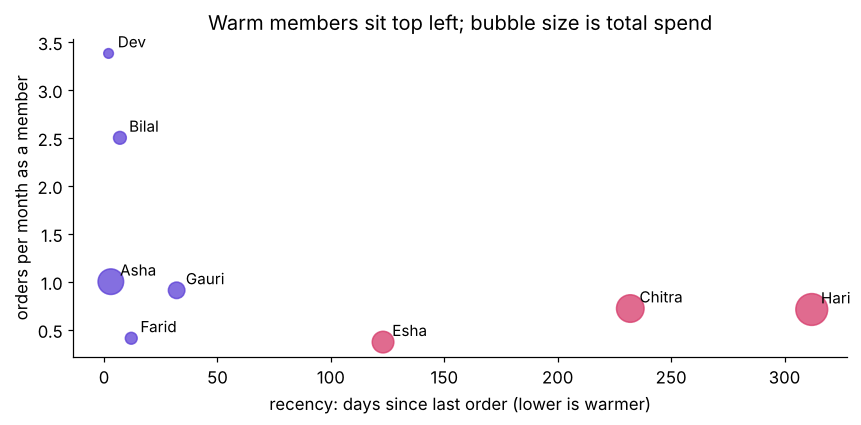

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(f["recency_days"], f["orders_per_month"], s=members["spend_rs"] / 60,
           color=[ROSE if r > 120 else VIOLET for r in f["recency_days"]], alpha=0.75)
for _, r in f.iterrows():
    ax.annotate(r["member"], (r["recency_days"], r["orders_per_month"]), xytext=(6, 4),
                textcoords="offset points", fontsize=10)
ax.set_xlabel("recency: days since last order (lower is warmer)")
ax.set_ylabel("orders per month as a member")
ax.set_title("Warm members sit top left; bubble size is total spend")
plt.tight_layout(); plt.show()

**The trap.** Hari's bubble is the biggest on the chart and sits far right: the largest
total, the coldest member. A model fed only `spend_rs` would rank Hari for a nudge, and
Kalpa would pay Rs 40 to reach the member least likely to answer it. Recency and
orders per month put Asha, Bilal and Dev ahead, which is what Marketing meant.

## Where are the same five ideas in the bank's file?
The bank's table already holds counts and a recency: `campaign` counts calls in this
campaign, `previous` counts calls in earlier campaigns, `pdays` is days since the last
contact (with 999 for never), and `poutcome` is how the last campaign ended.

**Predict before you run.** As `campaign` (calls so far this campaign) rises from 1 to 4 or
more, the yes-rate (A) rises, since persistence pays; (B) falls.

In [4]:
import io, zipfile, pathlib, urllib.request
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)
f_bank = CACHE / "bank-additional-full.csv"
if not f_bank.exists():   # the week's cached loader: UCI Bank Marketing, CC BY 4.0
    url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"  # verified 28 October 2026
    outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
    inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
    f_bank.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
bank = pd.read_csv(f_bank, sep=";")
yes = (bank["y"] == "yes")
calls = pd.cut(bank["campaign"], [0, 1, 2, 3, 100], labels=["1", "2", "3", "4 or more"])
earlier = pd.cut(bank["previous"], [-1, 0, 1, 100], labels=["0", "1", "2 or more"])
print("yes-rate by calls this campaign:", yes.groupby(calls, observed=True).mean().round(3).to_dict())
print("yes-rate by calls in earlier campaigns:", yes.groupby(earlier, observed=True).mean().round(3).to_dict())
print(f"pdays is 999 (never contacted) in {(bank['pdays'] == 999).mean():.1%} of rows")

yes-rate by calls this campaign: {'1': 0.13, '2': 0.115, '3': 0.107, '4 or more': 0.073}
yes-rate by calls in earlier campaigns: {'0': 0.088, '1': 0.212, '2 or more': 0.5}
pdays is 999 (never contacted) in 96.3% of rows


**What happened.** B. One call this campaign converts at about 13 percent and four or more
at about 7 percent: a count can carry signal in the direction nobody expected, which is why
each feature gets a reason and a check. Earlier contact helps sharply. `pdays` holds 999 for
96.3 percent of rows, a sentinel the case chapters split into a flag and a number.

In [5]:
check("Asha's average basket matches the hand count of Rs 700", f.loc[f["member"] == "Asha", "avg_basket_rs"].item() == 700)
check("Dev's recency is 2 days from the nudge morning", f.loc[f["member"] == "Dev", "recency_days"].item() == 2)
check("total spend ranks Hari first, recency ranks Hari last",
      members.sort_values("spend_rs").iloc[-1]["member"] == "Hari"
      and f.sort_values("recency_days").iloc[-1]["member"] == "Hari")
check("the bank's file loads with 41,188 rows", len(bank) == 41188)

PASS  Asha's average basket matches the hand count of Rs 700
PASS  Dev's recency is 2 days from the nudge morning
PASS  total spend ranks Hari first, recency ranks Hari last
PASS  the bank's file loads with 41,188 rows


## What are the rules, and what flips each one?
1. Measure every feature from the prediction moment. Computed from today's date, recency
   quietly uses days that had not happened when the nudge went out.
2. Prefer a ratio when members have different tenure; when everyone joined in the same
   window, the total and the ratio rank alike.
3. Count over a fixed window (orders in the last 90 days) when the decision is about the
   next 90 days; a lifetime count suits a loyalty tier.
4. A feature ships with its business reason; a feature nobody can explain is dropped, unless
   a fair test shows it carries signal the reasons missed.

Chapter 2 asks how a model reads the columns that are words, such as city and job.